# LeCun et al. (1998): aprender a reconocer documentos

**Gradient-Based Learning Applied to Document Recognition**  
Yann LeCun · Léon Bottou · Yoshua Bengio · Patrick Haffner

Este notebook explica las ideas del [paper proporcionado](lecun1998.pdf), con diagramas, seis animaciones y una CNN pequeña que realmente aprende. Las animaciones se pueden pausar y recorrer cuadro por cuadro.

La pregunta central es: **¿cómo sustituir parte de las reglas diseñadas a mano por parámetros que se aprenden a partir de ejemplos?** El paper responde en dos escalas:

- **Un carácter:** una red convolucional aprende representaciones útiles desde los píxeles.
- **Un documento:** varios módulos colaboran para escoger una interpretación y pueden ajustarse usando un objetivo global.

Los histogramas no son el método central del paper: resumen cantidades, pero para reconocer escritura también importa la distribución espacial.

Las figuras y animaciones están guardadas. Para regenerarlas, ejecuta las celdas en orden en Jupyter. Se requieren `numpy`, `matplotlib` e `IPython`; si faltan, `%pip install numpy matplotlib ipython` los instala. No se descarga MNIST ni se requiere GPU. Los valores dentro de las matrices se muestran redondeados a dos decimales; los cálculos conservan su precisión.

## 1. ¿Qué aprende el sistema?

En el enfoque supervisado de reconocimiento de dígitos, un ejemplo contiene **una imagen y su etiqueta**, como «7». La etiqueta se usa durante el entrenamiento; al reconocer una imagen nueva, el modelo solo recibe sus píxeles.

| Elemento | Significado |
|---|---|
| Entrada | Intensidades de los píxeles |
| Etiqueta | Respuesta correcta proporcionada para entrenar |
| Parámetros | Pesos y sesgos que se ajustan |
| Características internas | Respuestas calculadas a partir de patrones de la imagen |
| Pérdida | Medida de discrepancia entre la salida y la respuesta deseada |

**Un kernel es un conjunto de pesos; un mapa de características contiene sus respuestas en distintas posiciones.** No son lo mismo.

La analogía es aprender a revisar firmas: en lugar de recibir una lista exhaustiva de reglas para cada trazo, se observan ejemplos y correcciones. En la red, esa corrección es numérica. No implica comprensión humana ni que las etiquetas aparezcan solas.

Los filtros no tienen nombres obligatorios como «esquina» o «círculo». Algunas respuestas pueden parecer detectores de bordes o trazos; otras son combinaciones difíciles de describir. Se aprenden porque ayudan a reducir el error de la tarea. **Fuente: §I y §II-A, PDF pp. 2–8.**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle, FancyBboxPatch, FancyArrowPatch
from IPython.display import HTML, display

plt.rcParams.update({"font.size": 10, "figure.dpi": 90, "animation.embed_limit": 80})
AZUL, NARANJA, MORADO = "#167d9a", "#d97706", "#a21caf"


def matriz(ax, datos, titulo, firmado=False, limite=1, numeros=None):
    ax.clear()
    datos = np.asarray(datos, dtype=float)
    cmap = plt.get_cmap("RdBu" if firmado else "gray").copy()
    cmap.set_bad("#e2e8f0")
    ax.imshow(np.ma.masked_invalid(datos), cmap=cmap,
              vmin=-limite if firmado else 0, vmax=limite)
    if numeros is None:
        numeros = max(datos.shape) <= 6
    if numeros:
        for (i, j), v in np.ndenumerate(datos):
            label = "·" if np.isnan(v) else ("0" if abs(v) < 0.005 else f"{v:.2f}".rstrip("0").rstrip("."))
            blanco = not np.isnan(v) and ((firmado and abs(v) > 0.65*limite) or (not firmado and v < 0.5))
            ax.text(j, i, label, ha="center", va="center", color="white" if blanco else "#182536", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xticks(np.arange(-0.5, datos.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, datos.shape[0]), minor=True)
    ax.grid(which="minor", color="#94a3b8", linewidth=0.5)
    ax.tick_params(which="both", length=0)
    ax.set_title(titulo, pad=12)


def marco(ax, fila, columna, tamaño=1):
    ax.add_patch(Rectangle((columna-0.48, fila-0.48), tamaño-0.04, tamaño-0.04,
                           fill=False, edgecolor=MORADO, linewidth=3))


def animar(fig, actualizar, cuadros, intervalo=850):
    animacion = FuncAnimation(fig, actualizar, frames=cuadros, interval=intervalo,
                              repeat=False, blit=False)
    contenido = animacion.to_jshtml(default_mode="once")
    plt.close(fig)
    display(HTML(contenido))


def caja(ax, x, y, ancho, alto, texto, activo=False, color=AZUL):
    ax.add_patch(FancyBboxPatch((x,y), ancho, alto, boxstyle="round,pad=0.02",
                 facecolor="#d9f0f2" if activo else "#f1f5f9", edgecolor=color if activo else "#94a3b8", linewidth=2 if activo else 1))
    ax.text(x+ancho/2, y+alto/2, texto, ha="center", va="center", fontsize=10)


## 2. LeNet-5: una arquitectura diseñada para imágenes

El paper combina tres ideas:

1. **Conexiones locales:** cada unidad examina una región, no todos los píxeles.
2. **Pesos compartidos:** el mismo filtro se aplica en todas las posiciones de un mapa. Una característica útil no necesita aprenderse de nuevo para cada lugar.
3. **Subsampling:** reduce la resolución espacial para conservar respuestas más generales y disminuir sensibilidad a pequeñas variaciones.

Convolución no significa invariancia exacta: desplazar una imagen tiende a desplazar sus mapas, sujeto a bordes y pasos. Reducir resolución también pierde detalle.

La animación siguiente recorre **la arquitectura del paper**, no los datos de una simulación. **Fuente: figura 2 y §II-A/B, [PDF pp. 7–9](lecun1998.pdf#page=7).**

In [2]:
capas = [
    ("Entrada", "32 × 32", "Una imagen normalizada y centrada."),
    ("C1", "6 × 28 × 28", "Seis filtros de 5×5 producen seis mapas; los pesos se comparten por mapa."),
    ("S2", "6 × 14 × 14", "Subsampling de 2×2: menor resolución; el módulo original tiene parámetros entrenables."),
    ("C3", "16 × 10 × 10", "Combina regiones de varios mapas anteriores mediante filtros de 5×5."),
    ("S4", "16 × 5 × 5", "Otra reducción espacial de 2×2."),
    ("C5", "120 × 1 × 1", "Cada filtro abarca los 16 mapas de 5×5 y produce una respuesta."),
    ("F6", "84 unidades", "Combina las respuestas en una representación de 84 componentes."),
    ("Salida RBF", "10 penalizaciones", "Para dígitos, compara la representación con diez códigos de clase: menor distancia es mejor."),
]
fig, ax = plt.subplots(figsize=(13, 3.5))
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.3, top=0.87)
explicacion = fig.text(0.5, 0.10, "", ha="center", fontsize=11)


def arquitectura_cuadro(n):
    ax.clear(); ax.set(xlim=(-0.1,12.1), ylim=(-0.3,1.5)); ax.axis("off")
    for i, (nombre, forma, _) in enumerate(capas):
        x = i*1.5
        caja(ax, x, 0.2, 1.25, 0.85, f"{nombre}\n{forma}", activo=i==n)
        if i < 7:
            ax.annotate("", xy=(x+1.48,0.62), xytext=(x+1.27,0.62), arrowprops={"arrowstyle":"->","color":"#64748b"})
    ax.set_title("LeNet-5 original · dimensiones reales · recorrido conceptual")
    explicacion.set_text(capas[n][2])


animar(fig, arquitectura_cuadro, len(capas), intervalo=1600)

Animación con controles

**Detalles históricos que importan:** C3 no conecta todos los mapas de S2 con todos los mapas de salida; utiliza conexiones parciales. Las activaciones son de tipo tangente hiperbólica escalada. El subsampling original combina una suma local, un coeficiente y un sesgo entrenables, seguidos de una activación; no es simplemente max-pooling. La salida descrita utiliza distancias RBF, no la capa softmax de nuestra demostración posterior.

C1 tiene `6 × (5×5 + 1) = 156` parámetros entrenables. Cada filtro y su sesgo se reutilizan en 28×28 ubicaciones. El ahorro viene de compartir los pesos, no de que se omitan posiciones.

## 3. Ver la operación local: una ventana, un filtro y una suma

Para poder revisar las cuentas usamos una imagen de **8×8** y un filtro de **3×3 elegido a mano**. Esto ilustra una operación; no reproduce los tamaños de LeNet-5.

El filtro resta intensidad a la izquierda y la suma a la derecha. La animación muestra cada recorte, sus productos y la respuesta que se guarda. Los números negativos y positivos son respuestas, no probabilidades.

In [3]:
imagen_demo = np.zeros((8, 8))
imagen_demo[1, 2:6] = 1
imagen_demo[2, 5] = 1
imagen_demo[3:5, 4] = 1
imagen_demo[5:7, 3] = 1
kernel_demo = np.array([[-1., 0., 1.]] * 3)


def correlacion(imagen, kernel):
    ventanas = sliding_window_view(imagen, kernel.shape)
    return np.sum(ventanas * kernel, axis=(-2, -1))


mapa_demo = correlacion(imagen_demo, kernel_demo)
print("Imagen:", imagen_demo.shape, "→ mapa:", mapa_demo.shape)

Imagen: (8, 8) → mapa: (6, 6)


In [4]:
fig, ejes = plt.subplots(1, 4, figsize=(12, 4))
fig.subplots_adjust(bottom=0.25, top=0.8, wspace=0.3)
estado = fig.text(0.5, 0.07, "", ha="center", fontsize=11)


def convolucion_cuadro(n):
    fila, columna = divmod(n, 6)
    region = imagen_demo[fila:fila+3, columna:columna+3]
    productos = region * kernel_demo
    parcial = np.full((6, 6), np.nan)
    parcial.ravel()[:n+1] = mapa_demo.ravel()[:n+1]
    matriz(ejes[0], imagen_demo, "1. Región de 3×3")
    marco(ejes[0], fila, columna, 3)
    matriz(ejes[1], kernel_demo, "2. Mismos pesos", firmado=True)
    matriz(ejes[2], productos, "3. Píxel × peso", firmado=True)
    matriz(ejes[3], parcial, "4. Suma → mapa", firmado=True, limite=3)
    marco(ejes[3], fila, columna)
    estado.set_text(f"Posición ({fila}, {columna}) · suma de 9 productos = {productos.sum():g}\nLos puntos son casillas aún no calculadas; azul = positivo, rojo = negativo.")


animar(fig, convolucion_cuadro, 36, intervalo=450)

Animación con controles

El mismo kernel produce respuestas en todas las posiciones. Otros kernels producirían otros mapas. Una capa convolucional añade sesgos y una activación no lineal; el mapa anterior solo muestra la suma ponderada.

Esta operación, sin voltear el kernel, es técnicamente correlación cruzada. Es la convención habitual de las capas llamadas convolucionales.

## 4. Subsampling y activación: conservar información útil con menos detalle

Un promedio de 2×2 sustituye cuatro valores por uno. Pasamos de 6×6 a 3×3. Esto conserva una respuesta regional y pierde precisión espacial.

La animación muestra **solo el promedio**, que usaremos en la CNN pequeña. En LeNet-5 el módulo de subsampling además tiene un coeficiente, un sesgo y una activación entrenables. La suma y el promedio difieren por un factor absorbible en el coeficiente. **Fuente: §II-A/B, PDF pp. 8–9.**

In [5]:
def promedio_2x2(mapa):
    alto, ancho = mapa.shape
    return mapa.reshape(alto//2, 2, ancho//2, 2).mean(axis=(1, 3))


mapa_reducido = promedio_2x2(mapa_demo)
print(mapa_reducido)

[[ 1.    0.75 -1.75]
 [ 0.25  1.   -1.25]
 [ 1.   -0.75 -0.25]]


In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(8, 4.2))
fig.subplots_adjust(bottom=0.24, top=0.80, wspace=0.4)
estado = fig.text(0.5, 0.07, "", ha="center", fontsize=11)


def promedio_cuadro(n):
    i, j = divmod(n, 3)
    bloque = mapa_demo[2*i:2*i+2, 2*j:2*j+2]
    parcial = np.full((3, 3), np.nan)
    parcial.ravel()[:n+1] = mapa_reducido.ravel()[:n+1]
    matriz(ejes[0], mapa_demo, "Mapa: 6×6", firmado=True, limite=3)
    marco(ejes[0], 2*i, 2*j, 2)
    matriz(ejes[1], parcial, "Promedios: 3×3", firmado=True, limite=3)
    marco(ejes[1], i, j)
    valores = " + ".join(f"({v:g})" for v in bloque.ravel())
    estado.set_text(f"[{valores}] / 4 = {bloque.mean():g}\nMenos resolución no significa invariancia perfecta a desplazamientos.")


animar(fig, promedio_cuadro, 9, intervalo=1200)

Animación con controles

La **activación no lineal** permite que varias capas representen algo más que una única transformación lineal. La tangente hiperbólica conserva el signo y comprime respuestas grandes. LeNet-5 usa una versión escalada; nuestra CNN usa `tanh` estándar.

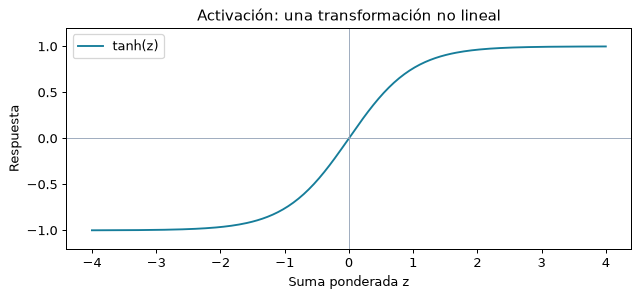

In [7]:
valores = np.linspace(-4, 4, 200)
fig, ax = plt.subplots(figsize=(7, 3.2), layout="constrained")
ax.plot(valores, np.tanh(valores), color=AZUL, label="tanh(z)")
ax.axhline(0, color="#94a3b8", linewidth=0.7); ax.axvline(0, color="#94a3b8", linewidth=0.7)
ax.set(xlabel="Suma ponderada z", ylabel="Respuesta", title="Activación: una transformación no lineal", ylim=(-1.2, 1.2))
ax.legend(); plt.show()

## 5. ¿Cómo decidía la clase la salida original?

En la arquitectura descrita, F6 produce 84 valores. Para cada clase, una unidad RBF calcula la **suma de diferencias al cuadrado** respecto a un código de referencia. Menor penalización indica mayor compatibilidad. Esas salidas no son probabilidades normalizadas.

La figura siguiente reduce la representación a dos componentes y tres códigos inventados para visualizar la distancia. No son códigos ni predicciones extraídos de LeNet-5. **Fuente: §II-B, ecuación 7, [PDF p. 9](lecun1998.pdf#page=9).**

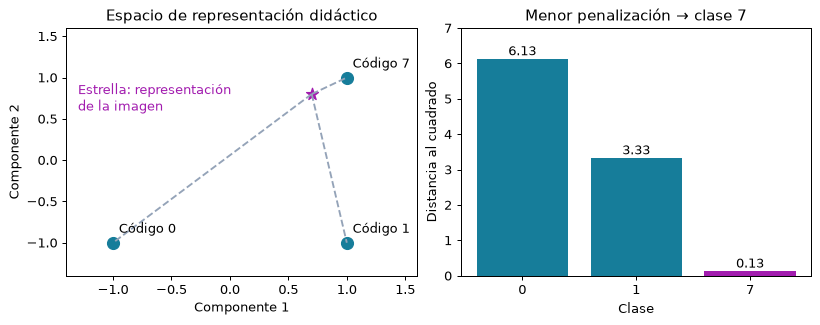

In [8]:
codigos = np.array([[-1., -1.], [1., -1.], [1., 1.]])
representacion = np.array([0.7, 0.8])
clases = np.array([0, 1, 7])
penalizaciones = np.sum((codigos - representacion) ** 2, axis=1)
fig, ejes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
ax = ejes[0]
for etiqueta, punto in zip(clases, codigos):
    ax.scatter(*punto, s=90, color=AZUL)
    ax.text(punto[0]+0.05, punto[1]+0.12, f"Código {etiqueta}")
    ax.plot([representacion[0], punto[0]], [representacion[1], punto[1]], color="#94a3b8", linestyle="--")
ax.scatter(*representacion, s=100, color=MORADO, marker="*")
ax.text(-1.3, 0.6, "Estrella: representación\nde la imagen", color=MORADO)
ax.set(xlim=(-1.4, 1.6), ylim=(-1.4, 1.6), xlabel="Componente 1", ylabel="Componente 2", title="Espacio de representación didáctico")
ax = ejes[1]
ax.bar(clases.astype(str), penalizaciones, color=[AZUL, AZUL, MORADO])
for i, p in enumerate(penalizaciones): ax.text(i, p+0.1, f"{p:.2f}", ha="center")
ax.set(ylim=(0,7), xlabel="Clase", ylabel="Distancia al cuadrado", title="Menor penalización → clase 7")
plt.show()

## 6. Una CNN pequeña que sí aprende desde píxeles

Construimos **una demostración inspirada en las ideas del paper**, con 151 parámetros:

**8×8 → 4 filtros de 3×3 + tanh → 4 mapas de 6×6 → promedio 2×2 → 36 valores → 3 clases.**

| LeNet-5 del paper | Demostración |
|---|---|
| Imágenes 32×32; diez dígitos | Imágenes 8×8; clases 0, 1 y 7 |
| Varias capas convolucionales | Una capa con cuatro filtros |
| Subsampling con parámetros entrenables | Promedio fijo de 2×2 |
| Tangente hiperbólica escalada | `tanh` estándar |
| Salida RBF y criterios descritos en §II-C | Softmax y entropía cruzada |

La simplificación de la salida facilita ver probabilidades y entrenar una red pequeña. **No es una reproducción exacta de LeNet-5 ni de sus resultados.**

Creamos 90 ejemplos para entrenar y 45 ejemplos nuevos para evaluar. Provienen de tres plantillas con desplazamientos, cambios de intensidad y ruido. Son datos sintéticos sencillos; no escritura real ni MNIST.

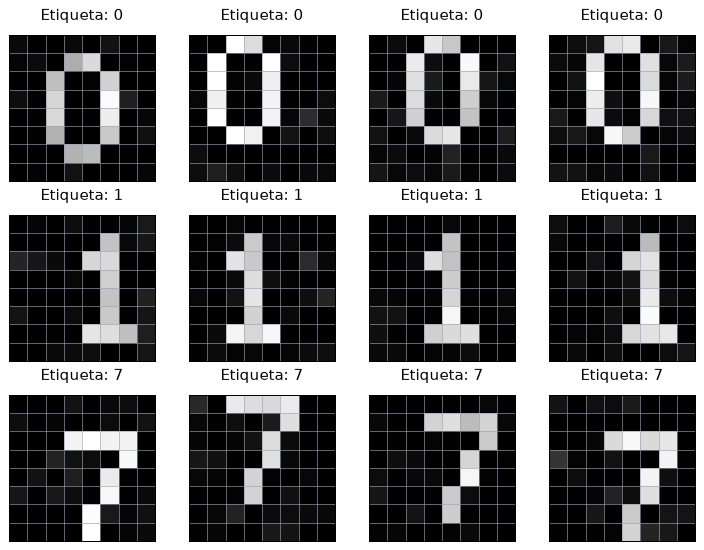

In [9]:
plantillas = np.array([
    [[0,1,1,0], [1,0,0,1], [1,0,0,1], [1,0,0,1], [1,0,0,1], [0,1,1,0]],
    [[0,0,1,0], [0,1,1,0], [0,0,1,0], [0,0,1,0], [0,0,1,0], [0,1,1,1]],
    [[1,1,1,1], [0,0,0,1], [0,0,1,0], [0,0,1,0], [0,1,0,0], [0,1,0,0]],
], dtype=float)


def crear_datos(por_clase, semilla):
    rng = np.random.default_rng(semilla)
    imagenes, etiquetas = [], []
    for etiqueta, plantilla in enumerate(plantillas):
        for _ in range(por_clase):
            imagen = np.zeros((8, 8))
            imagen[1:7, 2:6] = plantilla
            imagen = np.roll(imagen, tuple(rng.integers(-1, 2, 2)), axis=(0, 1))
            imagen = np.clip(imagen*rng.uniform(0.75, 1) + rng.normal(0, 0.06, imagen.shape), 0, 1)
            imagenes.append(imagen); etiquetas.append(etiqueta)
    return np.array(imagenes), np.array(etiquetas)


X_train, y_train = crear_datos(30, 1998)
X_test, y_test = crear_datos(15, 2026)
fig, ejes = plt.subplots(3, 4, figsize=(8, 6), layout="constrained")
for fila in range(3):
    for columna in range(4):
        i = fila*30 + columna
        matriz(ejes[fila, columna], X_train[i], f"Etiqueta: {clases[y_train[i]]}")
plt.show()

### Propagación hacia delante: producir una respuesta

Los kernels empiezan con números aleatorios pequeños. No se entrega un detector de siete ya hecho. Cada filtro produce su propio mapa; las respuestas reducidas se combinan para obtener puntuaciones de clase. Softmax las transforma en valores positivos que suman uno.

`einsum` resume las multiplicaciones y sumas entre cada ventana y cada filtro: hace la misma operación de la animación anterior, para varias imágenes a la vez.

In [10]:
rng = np.random.default_rng(7)
parametros = {
    "K": rng.normal(0, 0.2, (4, 3, 3)),
    "b": np.zeros(4),
    "W": rng.normal(0, 0.15, (36, 3)),
    "c": np.zeros(3),
}
iniciales = {nombre: valor.copy() for nombre, valor in parametros.items()}


def predecir(X, p):
    ventanas = sliding_window_view(X, (3, 3), axis=(1, 2))
    sumas = np.einsum("nhwij,fij->nfhw", ventanas, p["K"]) + p["b"][None, :, None, None]
    activaciones = np.tanh(sumas)
    reducidas = activaciones.reshape(len(X), 4, 3, 2, 3, 2).mean(axis=(3, 5))
    vector = reducidas.reshape(len(X), 36)
    puntuaciones = vector @ p["W"] + p["c"]
    puntuaciones -= puntuaciones.max(axis=1, keepdims=True)
    exp = np.exp(puntuaciones)
    probabilidades = exp / exp.sum(axis=1, keepdims=True)
    return probabilidades, (ventanas, activaciones, reducidas, vector)


print("Parámetros entrenables:", sum(v.size for v in parametros.values()))

Parámetros entrenables: 151


### Retropropagación: asignar a cada parámetro su parte del error

La pérdida de clasificación es `−log(probabilidad de la clase correcta)`, promediada entre los ejemplos. Una respuesta correcta con probabilidad baja también recibe una penalización.

La **retropropagación calcula gradientes**, recorriendo las operaciones al revés mediante la regla de la cadena. Después, **el descenso por gradiente actualiza los parámetros**. Son dos pasos diferentes.

En el promedio, el gradiente se reparte entre cuatro entradas; en `tanh`, se multiplica por `1 − activación²`. Como un filtro se reutiliza en muchas posiciones, sus contribuciones al gradiente se suman.

In [11]:
def gradientes(probabilidades, memoria, etiquetas, p):
    ventanas, activaciones, reducidas, vector = memoria
    d_puntuaciones = probabilidades.copy()
    d_puntuaciones[np.arange(len(etiquetas)), etiquetas] -= 1
    d_puntuaciones /= len(etiquetas)
    d_vector = d_puntuaciones @ p["W"].T
    d_reducidas = d_vector.reshape(reducidas.shape)
    d_activaciones = np.repeat(np.repeat(d_reducidas, 2, axis=2), 2, axis=3) / 4
    d_sumas = d_activaciones * (1 - activaciones**2)
    return {
        "W": vector.T @ d_puntuaciones,
        "c": d_puntuaciones.sum(axis=0),
        "K": np.einsum("nfhw,nhwij->fij", d_sumas, ventanas),
        "b": d_sumas.sum(axis=(0, 2, 3)),
    }


prob_inicial, memoria_inicial = predecir(X_train, parametros)
grad_inicial = gradientes(prob_inicial, memoria_inicial, y_train, parametros)

In [12]:
nombres = ["Píxeles", "Convolución\n+ tanh", "Promedio\n2×2", "Clasificador\n+ softmax", "Pérdida\n+ etiqueta"]
mensajes = [
    "Entrada: imágenes con sus etiquetas de entrenamiento.",
    "Los filtros producen mapas; tanh transforma sus respuestas.",
    "El promedio reduce la resolución de los mapas.",
    "El clasificador produce una probabilidad por clase.",
    "La pérdida compara las probabilidades con la clase correcta.",
    "Retropropagación: la etiqueta determina cómo cambia la pérdida con la salida.",
    "El clasificador recibe su gradiente y transmite gradientes a las características.",
    "El promedio reparte el gradiente entre sus cuatro entradas.",
    "tanh aplica su derivada; las contribuciones de todas las ventanas actualizan el mismo kernel.",
    "Actualización: parámetros nuevos = parámetros actuales − paso × gradientes.",
]
fig, ax = plt.subplots(figsize=(11, 3.8))
fig.subplots_adjust(bottom=0.3, top=0.86, left=0.03, right=0.97)
estado = fig.text(0.5, 0.06, "", ha="center", fontsize=10)


def retro_cuadro(n):
    ax.clear(); ax.set(xlim=(-0.1, 10), ylim=(-0.3, 1.6)); ax.axis("off")
    activo = n if n < 5 else (9-n if n < 9 else -1)
    for i, nombre in enumerate(nombres):
        caja(ax, i*2, 0.25, 1.65, 0.8, nombre, activo=i==activo or n==9)
        if i < 4:
            izquierda, derecha = i*2+1.7, (i+1)*2-0.05
            inicio, fin = (izquierda, derecha) if n < 5 else (derecha, izquierda)
            ax.annotate("", xy=(fin, 0.65), xytext=(inicio, 0.65), arrowprops={"arrowstyle":"->", "color":AZUL if n<5 else MORADO, "lw":2})
    ax.set_title("Hacia delante: respuestas" if n < 5 else "Hacia atrás: gradientes" if n < 9 else "Actualizar los parámetros")
    estado.set_text(mensajes[n] + f"\nNormas del gradiente inicial: filtros = {np.linalg.norm(grad_inicial['K']):.3f}; clasificador = {np.linalg.norm(grad_inicial['W']):.3f}")


animar(fig, retro_cuadro, len(mensajes), intervalo=1400)

Animación con controles

### Entrenamiento conjunto: cambian los filtros y el clasificador

Aplicamos 200 actualizaciones sobre los 90 ejemplos de entrenamiento. Los ejemplos de evaluación nunca se usan para calcular gradientes. Guardamos estados intermedios para observar qué cambia.

La animación muestra un filtro, las probabilidades de un ejemplo nuevo de la clase 7 y la pérdida de entrenamiento. Los filtros no reciben etiquetas propias: se ajustan por su contribución a la clasificación final.

In [13]:
paso = 0.3
historial = []
perdidas = []
ejemplo_nuevo = X_test[30:31]

for iteracion in range(201):
    probabilidades, memoria = predecir(X_train, parametros)
    perdida = float(-np.log(probabilidades[np.arange(len(y_train)), y_train]).mean())
    perdidas.append(perdida)
    if iteracion % 5 == 0:
        prob_nueva, _ = predecir(ejemplo_nuevo, parametros)
        historial.append((iteracion, parametros["K"].copy(), prob_nueva[0].copy()))
    if iteracion < 200:
        g = gradientes(probabilidades, memoria, y_train, parametros)
        for nombre in parametros:
            parametros[nombre] -= paso * g[nombre]

prob_test, _ = predecir(X_test, parametros)
print(f"Aciertos en entrenamiento: {(probabilidades.argmax(1) == y_train).sum()}/{len(y_train)}")
print(f"Aciertos en evaluación sintética: {(prob_test.argmax(1) == y_test).sum()}/{len(y_test)}")

Aciertos en entrenamiento: 90/90
Aciertos en evaluación sintética: 45/45


In [14]:
fig, ejes = plt.subplots(1, 4, figsize=(12, 4.5))
fig.subplots_adjust(bottom=0.25, top=0.77, wspace=0.5)
estado = fig.text(0.5, 0.07, "", ha="center", fontsize=11)
limite_filtro = max(np.max(np.abs(k)) for _, k, _ in historial)


def entrenar_cuadro(n):
    iteracion, kernels, prob = historial[n]
    matriz(ejes[0], ejemplo_nuevo[0], "Imagen nueva: clase 7")
    matriz(ejes[1], kernels[0], "Filtro 1 aprendido", firmado=True, limite=limite_filtro)
    ax = ejes[2]; ax.clear()
    ax.bar(clases.astype(str), prob, color=[AZUL, AZUL, MORADO])
    ax.set(ylim=(0, 1.1), ylabel="Probabilidad", xlabel="Clase", title="Predicción del ejemplo")
    for i, valor in enumerate(prob): ax.text(i, valor+0.03, f"{valor:.2f}", ha="center", fontsize=9)
    ax = ejes[3]; ax.clear()
    ax.plot(range(iteracion+1), perdidas[:iteracion+1], color=AZUL)
    ax.scatter([iteracion], [perdidas[iteracion]], color=MORADO, zorder=4)
    ax.set(xlim=(0, 200), ylim=(0, 1.2), xlabel="Actualización", ylabel="Entropía cruzada", title="Pérdida de entrenamiento")
    estado.set_text(f"Actualización {iteracion}/200 · pérdida = {perdidas[iteracion]:.3f}\nLa etiqueta supervisa la salida; el gradiente ajusta todos los parámetros internos.")


animar(fig, entrenar_cuadro, len(historial), intervalo=500)

Animación con controles

### ¿Cuáles son las características aprendidas?

Cada filtro de 3×3 responde a combinaciones de intensidades. Sus mapas conservan dónde aparecen esas respuestas. El clasificador utiliza **36 valores**: cuatro mapas reducidos de 3×3.

Abajo se muestran los filtros iniciales y finales, y sus mapas para el ejemplo nuevo. No debemos asignar un nombre semántico preciso a cada filtro solo por su apariencia. Lo comprobable es que sus pesos cambiaron y que sus respuestas se combinan para resolver la tarea.

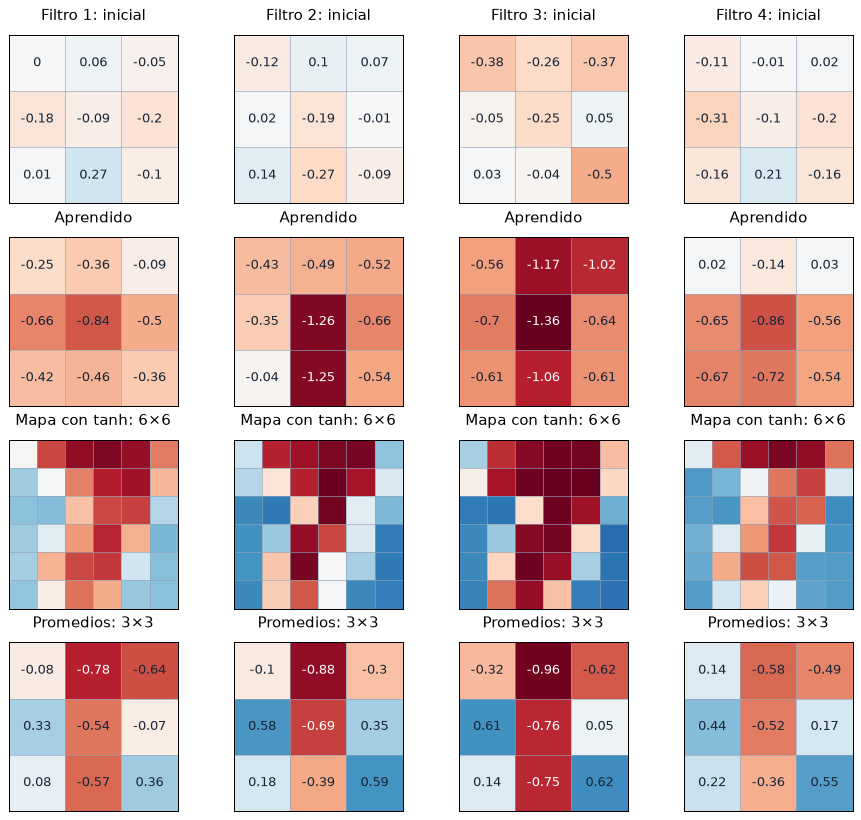

In [15]:
_, (_, activaciones_finales, reducidas_finales, _) = predecir(ejemplo_nuevo, parametros)
fig, ejes = plt.subplots(4, 4, figsize=(10, 9), layout="constrained")
limite = max(np.max(np.abs(iniciales["K"])), np.max(np.abs(parametros["K"])))
for i in range(4):
    matriz(ejes[0,i], iniciales["K"][i], f"Filtro {i+1}: inicial", firmado=True, limite=limite)
    matriz(ejes[1,i], parametros["K"][i], "Aprendido", firmado=True, limite=limite)
    matriz(ejes[2,i], activaciones_finales[0,i], "Mapa con tanh: 6×6", firmado=True, numeros=False)
    matriz(ejes[3,i], reducidas_finales[0,i], "Promedios: 3×3", firmado=True)
plt.show()

Los aciertos mostrados corresponden a variaciones sintéticas de tres plantillas. Aunque usamos ejemplos nuevos para evaluar, esto no demuestra reconocimiento de escritura real, ni reproduce el experimento del paper. La prueba del paper usa muchos escritores y un conjunto de dígitos considerablemente más diverso.

## 7. ¿Qué evidencia presenta el paper?

En el experimento de MNIST se usaron **60 000 imágenes de entrenamiento y 10 000 de prueba**. El paper reporta aproximadamente **0.95 % de error** para LeNet-5 sin distorsiones y **0.8 %** al entrenar con ejemplos distorsionados. Son resultados históricos del paper, no de este notebook.

Las distorsiones incluyen desplazamiento, escala, estiramiento y cizallamiento. Generar variaciones plausibles ayuda a enseñar qué cambios deberían conservar la etiqueta. La arquitectura por sí sola no elimina la necesidad de datos adecuados.

**Fuente: §III-A/B, figuras 5–8, [PDF pp. 11–13](lecun1998.pdf#page=11).**

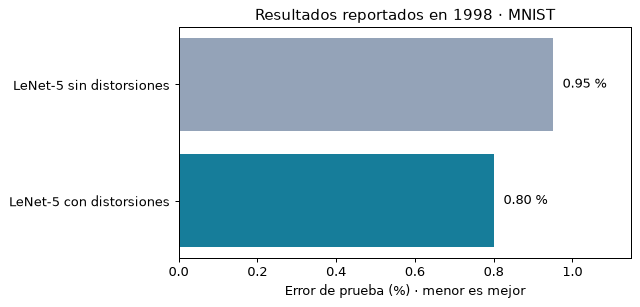

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.3), layout="constrained")
valores = [0.95, 0.8]
ax.barh(["LeNet-5 sin distorsiones", "LeNet-5 con distorsiones"], valores, color=["#94a3b8", AZUL])
for i, valor in enumerate(valores): ax.text(valor+0.025, i, f"{valor:.2f} %", va="center")
ax.set(xlim=(0, 1.15), xlabel="Error de prueba (%) · menor es mejor", title="Resultados reportados en 1998 · MNIST")
ax.invert_yaxis(); plt.show()

## 8. De un dígito a un documento: Graph Transformer Networks

Reconocer caracteres aislados no basta para leer un documento. Hay que localizar campos, decidir posibles cortes, reconocer fragmentos y aplicar restricciones de secuencia.

**Documento → campos candidatos → segmentaciones → caracteres con penalizaciones → secuencias compatibles → interpretación.**

Tomar una decisión irreversible demasiado pronto puede descartar la respuesta correcta. Las GTN representan varias hipótesis mediante **grafos dirigidos**, que cada módulo transforma. Una ruta completa representa una interpretación; su penalización combina evidencia de los módulos.

Aquí “transformer” significa transformar grafos de hipótesis: no es el Transformer moderno de atención.

### Una ambigüedad de juguete

Una región podría interpretarse como dos caracteres («1» y «2») o como un solo «7». Inventamos costos para mostrar la decisión:

- Ruta «12»: `0.25 + 0.30 = 0.55`.
- Ruta «7»: `0.10`.
- Regla de formato didáctica: el campo debe contener **exactamente dos dígitos**.

Sin la regla, la ruta «7» tiene menor costo. Al incorporar el formato, esa ruta deja de ser admisible y se elige «12». No decimos que esos números sean probabilidades ni resultados de un reconocedor real.

**Fuente: §IV–VI y §X, [PDF pp. 18–27](lecun1998.pdf#page=18) y [pp. 39–41](lecun1998.pdf#page=39).**

In [17]:
rutas = [
    {"texto": "12", "costos": [0.25, 0.30]},
    {"texto": "7", "costos": [0.10]},
]
mejor_sin_regla = min(rutas, key=lambda r: sum(r["costos"]))
admisibles = [r for r in rutas if len(r["texto"]) == 2]
mejor_con_regla = min(admisibles, key=lambda r: sum(r["costos"]))
print("Sin formato:", mejor_sin_regla["texto"])
print("Con formato de dos dígitos:", mejor_con_regla["texto"])

Sin formato: 7
Con formato de dos dígitos: 12


In [18]:
fig, ax = plt.subplots(figsize=(10, 4.5))
fig.subplots_adjust(bottom=0.25, top=0.82)
estado = fig.text(0.5, 0.07, "", ha="center", fontsize=11)
pasos_gtn = [
    "Conservar alternativas: un fragmento grande o dos fragmentos pequeños.",
    "El reconocedor asigna etiquetas y penalizaciones a los arcos.",
    "Sin restricciones: la ruta 7 tiene menor penalización (0.10).",
    "El formato exige dos dígitos: la ruta de un solo carácter queda excluida.",
    "La ruta admisible de menor penalización es 12: 0.25 + 0.30 = 0.55.",
]


def grafo_cuadro(n):
    ax.clear(); ax.set(xlim=(-0.5, 4.5), ylim=(-1.35, 1.2)); ax.axis("off")
    for x, etiqueta in [(0,"Inicio"),(2,"Corte posible"),(4,"Final")]:
        ax.scatter([x], [0], s=500, color="#e2e8f0", edgecolor="#64748b", zorder=4)
        ax.text(x, -0.35, etiqueta, ha="center")
    color_superior = MORADO if n == 4 else AZUL
    for origen, destino, label in [(0,2,"1 · 0.25"),(2,4,"2 · 0.30")]:
        ax.add_patch(FancyArrowPatch((origen+0.12,0.10),(destino-0.12,0.10),connectionstyle="arc3,rad=-0.25",arrowstyle="->",mutation_scale=15,lw=3 if n==4 else 2,color=color_superior))
        ax.text((origen+destino)/2, 0.47, label if n>=1 else "fragmento", ha="center")
    color_inferior = MORADO if n==2 else "#cbd5e1" if n>=3 else NARANJA
    ax.add_patch(FancyArrowPatch((0.1,-0.08),(3.9,-0.08),connectionstyle="arc3,rad=0.35",arrowstyle="->",mutation_scale=15,lw=3 if n==2 else 2,color=color_inferior,linestyle="--" if n>=3 else "-"))
    ax.text(2, -1.18, "7 · 0.10" + (" · excluida por formato" if n>=3 else "") if n>=1 else "fragmento completo", ha="center", color="#64748b" if n>=3 else color_inferior)
    ax.set_title("Varias segmentaciones e interpretaciones en un grafo")
    estado.set_text(pasos_gtn[n])


animar(fig, grafo_cuadro, len(pasos_gtn), intervalo=1700)

Animación con controles

El ejemplo enumera dos rutas. En grafos grandes, el algoritmo de Viterbi encuentra la ruta de menor penalización acumulada mediante programación dinámica. La animación solo muestra decodificación con costos inventados: **no entrena una GTN**.

### El aporte adicional: entrenar con un objetivo global

El paper también describe cómo entrenar usando la **secuencia correcta completa**, sin requerir que cada carácter tenga su corte etiquetado. Compara las hipótesis compatibles con la respuesta correcta con el conjunto de hipótesis posibles y propaga gradientes hacia los módulos que producen las penalizaciones.

Así, una mejora local no se toma automáticamente como una mejora del documento: el objetivo mide la interpretación final. El artículo desarrolla criterios Viterbi y criterios forward, incluidos criterios discriminativos que consideran rutas alternativas.

En el sistema de cheques (§X), se combinan localización de campos, segmentación, reconocimiento con LeNet-5, restricciones de formato y selección de rutas. El texto describe inicialización por módulos y posterior ajuste global; no significa que todas las heurísticas desaparezcan ni que en cada experimento todos los parámetros se entrenaran conjuntamente.

## 9. Qué aporta el paper y qué demuestra este notebook

| Idea del paper | Evidencia visual o ejecutable aquí |
|---|---|
| Usar estructura local de las imágenes | Ventana de convolución |
| Compartir pesos entre posiciones | El mismo kernel llena un mapa completo |
| Reducir resolución y combinar respuestas | Promedios 2×2 y clasificador |
| Aprender características desde la tarea | Cuatro filtros cambian por el error de clasificación |
| Propagar gradientes entre módulos | Recorrido hacia delante y hacia atrás |
| Mantener hipótesis de segmentación y reconocimiento | Grafo con rutas alternativas |
| Optimizar un sistema por su resultado final | Explicación de entrenamiento global; la GTN no se implementa |

**La idea común es ajustar parámetros a partir del error de la tarea, en lugar de diseñar manualmente cada característica y cada decisión.** La arquitectura, los datos y el objetivo siguen siendo decisiones humanas.

### Fuente y alcance

LeCun, Y., Bottou, L., Bengio, Y. y Haffner, P. (1998). *Gradient-Based Learning Applied to Document Recognition*. Proceedings of the IEEE, 86(11), 2278–2324. DOI: 10.1109/5.726791. [PDF local](lecun1998.pdf).

Las referencias de página usan el contador del PDF proporcionado, incluida su portada HAL. Las figuras y los datos sintéticos de este notebook son ilustraciones nuevas. La CNN de 151 parámetros es una demostración pedagógica, no una reproducción de LeNet-5, MNIST ni del sistema de cheques.